# Exercise 4.3.12 (Tikhonov Regularization)

Using the results of \Cref{ex: quadratic regularization}, implement Tikhonov regularization with $\alpha=5 \cdot10^{-4}$ in two ways: Based on gradient descent with $K = 10^5$ iterations and convergence threshold $\varepsilon = 10^{-8}$, and using the SVD.
For a Gaussian matrix $A \in \mathbb R^{M \times N}$ with $A_{k,j} \sim M^{-1/2} \mathcal N(0,1)$ and 
$$
(x_*)_k = \sin(2 \pi k / N) + 0.5 \sin(6 \pi k / N)  - 0.2 \sin(40 \pi k / N) + 0.3 \sin(10 \pi k / N),
\quad k = 0, \ldots, N-1,
$$
we consider the  inverse problem $Ax = y$.
Perform the reconstruction for $N =2^n$ and $M =3 \cdot 2^n$ with $n =2,\ldots,11$.
Compare the runtime of both approaches.
Does gradient descent admit a nice convergence behavior? 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from timeit import default_timer as timer

In [2]:
def gradient_descent(x0, nu, grad, loss, num_iter, it_thr = 0, xt = None):
    x = x0
    loss_base = loss(np.zeros_like(x0))
    m_error = np.zeros((num_iter + 1))
    
    m_error[0] = loss(x0) / loss_base
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

    for k in range(num_iter):
        grad_x = grad(x)
        x = x - nu*grad_x 

        m_error[k+1] = loss(x) / loss_base
        if xt is not None:
            error[k+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

        if it_thr > 0 and np.linalg.norm(grad_x) < it_thr:
            break
        
    if xt is not None:
        return x, m_error, error
    else:
        return x, m_error

In [3]:
M_list = 2**np.arange(2,12)
runtimes = np.zeros((2, len(M_list)))
num_iter = 100000
errors = np.zeros((len(M_list), num_iter+1))
obj_errors = np.zeros((len(M_list), num_iter+1)) 
labels = [] 
for im in range(len(M_list)):
    M = 3*M_list[im]
    N = M_list[im]

    labels += [f"(M,N) = {M,N}"]
    A = np.random.randn(M,N) / np.sqrt(M)

    idx = np.arange(N)
    f = np.sin( 2 * np.pi * idx / N) + 0.5 *np.sin( 6 * np.pi * idx / N) 
    f = f - 0.2 * np.sin( 40 * np.pi * idx / N) + 0.3 * np.sin( 10 * np.pi * idx / N)
    
    y = A @ f
    x0 = np.random.randn((N))
    
    alph = 0.0005
    # Tikhonov
    grad = lambda x: A.T @( A @ x - y) + alph * x
    loss = lambda x: 0.5*np.linalg.norm(A@x - y)**2 + 0.5*alph * np.linalg.norm(x)**2
    nu = 1.0 / (np.linalg.norm(A,2)**2 + alph)

    start = timer()
    x1, m_errors, obj_er  = gradient_descent(x0, 0.9*nu, grad, loss,num_iter, 1e-8, f)
    errors[im,:] = m_errors
    obj_errors[im,:] = obj_er
    end = timer()
    runtimes[0,im] = end - start 

    start = timer()
    K = A.T @ A + alph*np.eye(N) # Kx = A^T y
    s, U = np.linalg.eig(K) # K = U diag(s) U^T
    ps_x = U @ ((U.T @ A.T @ y) / s) 
    end = timer()
    runtimes[1,im] = end - start 

    print(f"Runtime, M = {M}, GD: {runtimes[0,im]:.2f}, SVD: {runtimes[1,im]:.2f} ")

Runtime, M = 12, GD: 0.01, SVD: 0.00 
Runtime, M = 24, GD: 0.01, SVD: 0.00 
Runtime, M = 48, GD: 0.02, SVD: 0.00 
Runtime, M = 96, GD: 0.02, SVD: 0.00 
Runtime, M = 192, GD: 0.08, SVD: 0.00 
Runtime, M = 384, GD: 0.17, SVD: 0.03 
Runtime, M = 768, GD: 0.31, SVD: 0.51 
Runtime, M = 1536, GD: 1.04, SVD: 2.24 
Runtime, M = 3072, GD: 2.00, SVD: 97.36 
Runtime, M = 6144, GD: 6.37, SVD: 779.87 


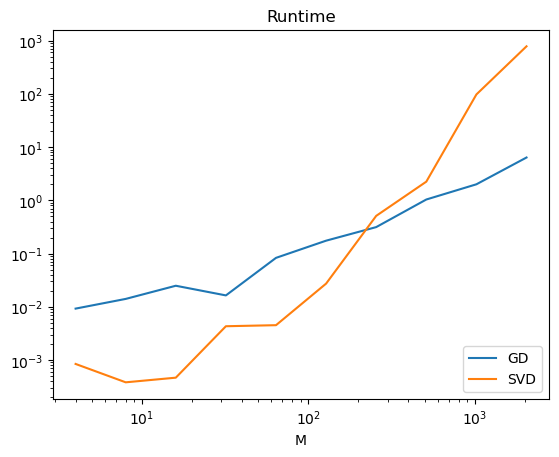

In [4]:
plt.loglog(M_list, runtimes.T)
plt.title(r'Runtime')
plt.xlabel('M')
plt.legend(["GD", "SVD"], loc = 'lower right')
plt.show()

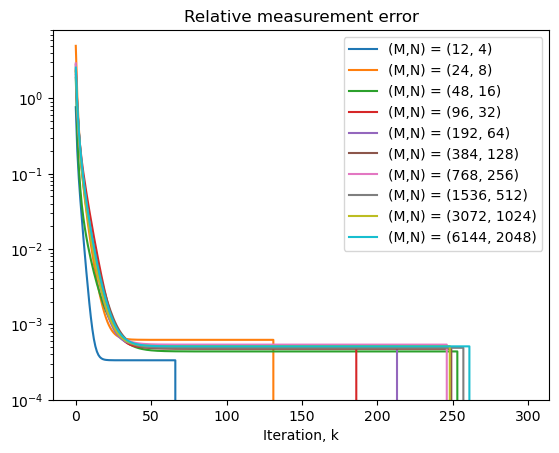

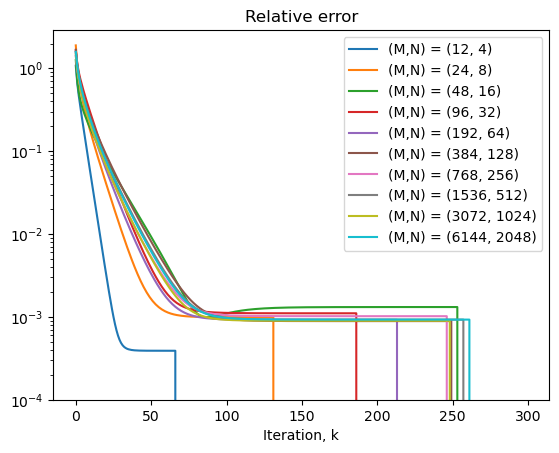

In [5]:
plt.semilogy(errors.T[:300,:])
plt.legend(labels, loc = 'upper right')
plt.title('Relative measurement error')
plt.xlabel('Iteration, k')
plt.ylim(bottom=1e-4)
plt.show()


plt.semilogy(obj_errors.T[:300,:])
plt.legend(labels, loc = 'upper right')
plt.title('Relative error')
plt.xlabel('Iteration, k')
plt.ylim(bottom=1e-4)
plt.show()